In [1]:
suppressPackageStartupMessages({
library(Seurat)
library(SeuratWrappers)
library(patchwork)
library(dplyr)
library(ggplot2)
library(dittoSeq)
library(scales)
})

theme_set(theme_classic(16))

# Set working directory for saving and accessing files
setwd("/data/pam/team333/skb/scratch/SNIP_paper/")
set.seed(123)

In [2]:
Hcon_obj <- readRDS(file = "04_analysis/seurat_obj/Hcon_harmony.rds")

In [4]:
table(Hcon_obj@meta.data$sample)


 HconF_1  HconF_2 HconL3_1 HconL3_2  HconM_1  HconM_2 
     509     6005      610     2421      214      816 

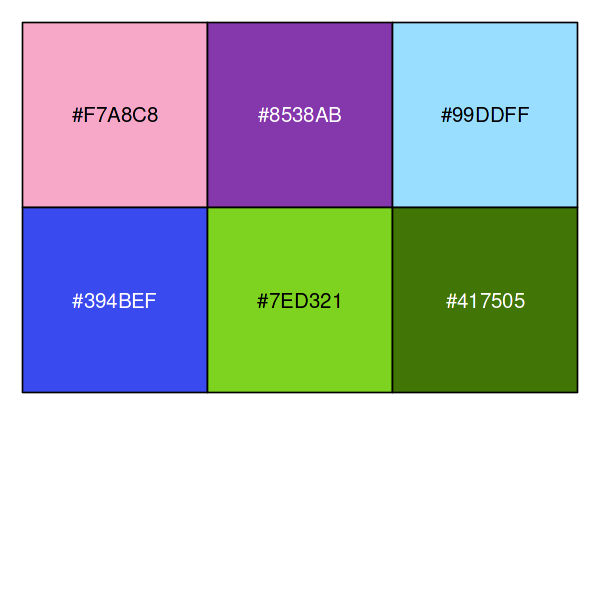

In [90]:
#Sample colors to use
options(repr.plot.width=5, repr.plot.height=5)
stage_cols <- c(
    "HconF_1" = "#F7A8C8",
    "HconF_2" = "#8538AB",
    "HconM_1" = "#99DDFF",
    "HconM_2" = "#394BEF",
    "HconL3_1" = "#7ED321",
    "HconL3_2" = "#417505")

show_col(stage_cols)

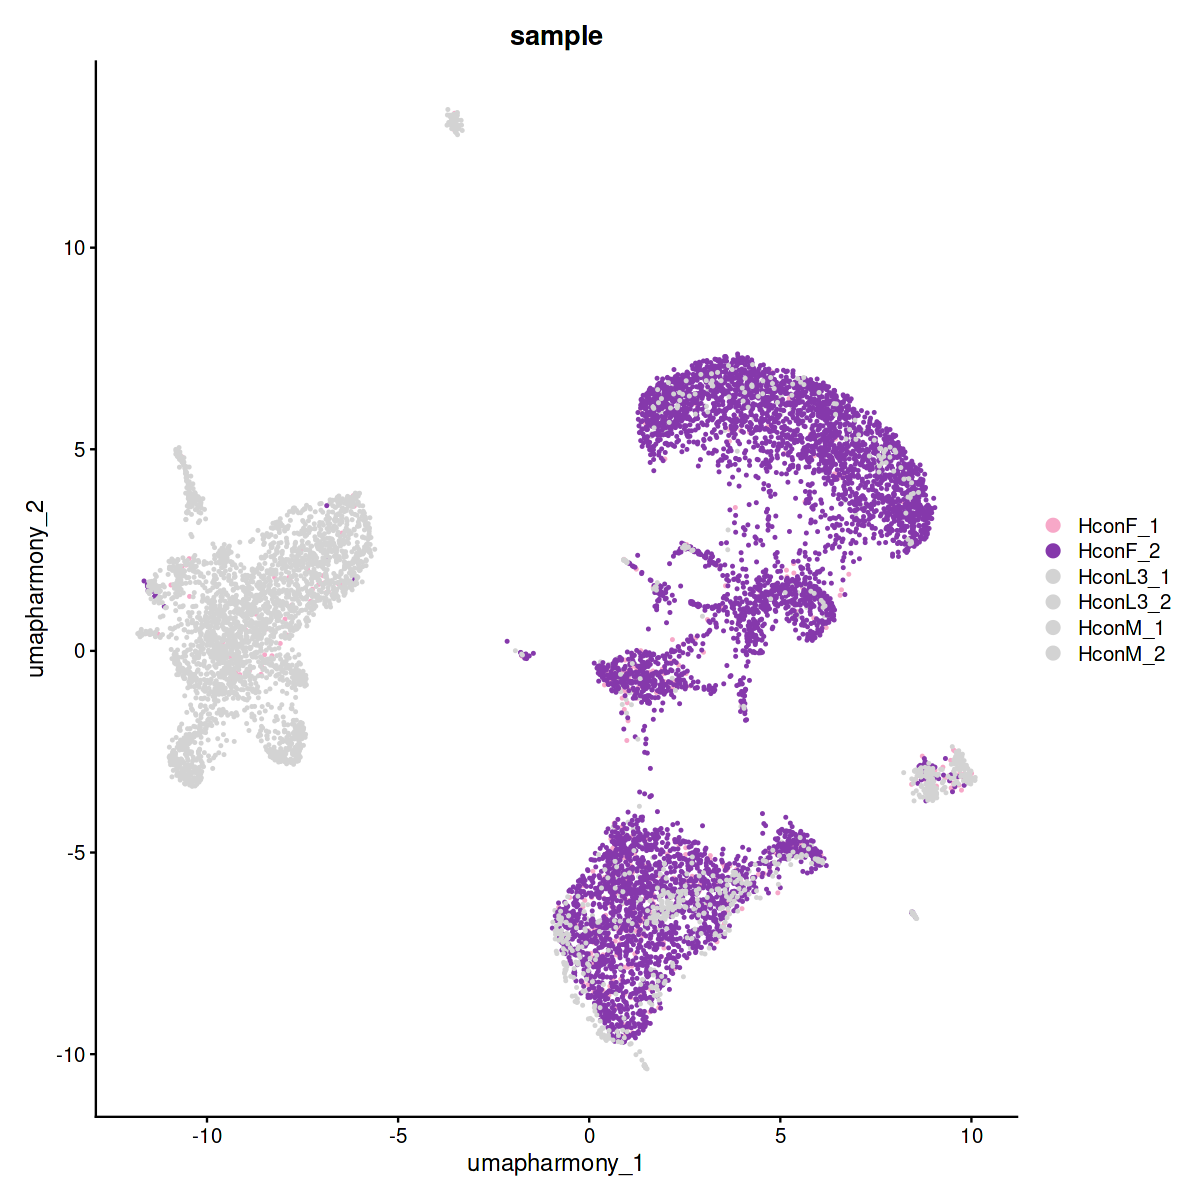

In [101]:
# Hcon harmony-integrated UMAP by kit
options(repr.plot.width=10, repr.plot.height=10)
DimPlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE, 
        group.by = "sample",
        cols = stage_cols)
ggsave(file = "05_figures/hcon_UMAP_kit.png", width = 20, height = 20, dpi = 600, units = "cm")

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


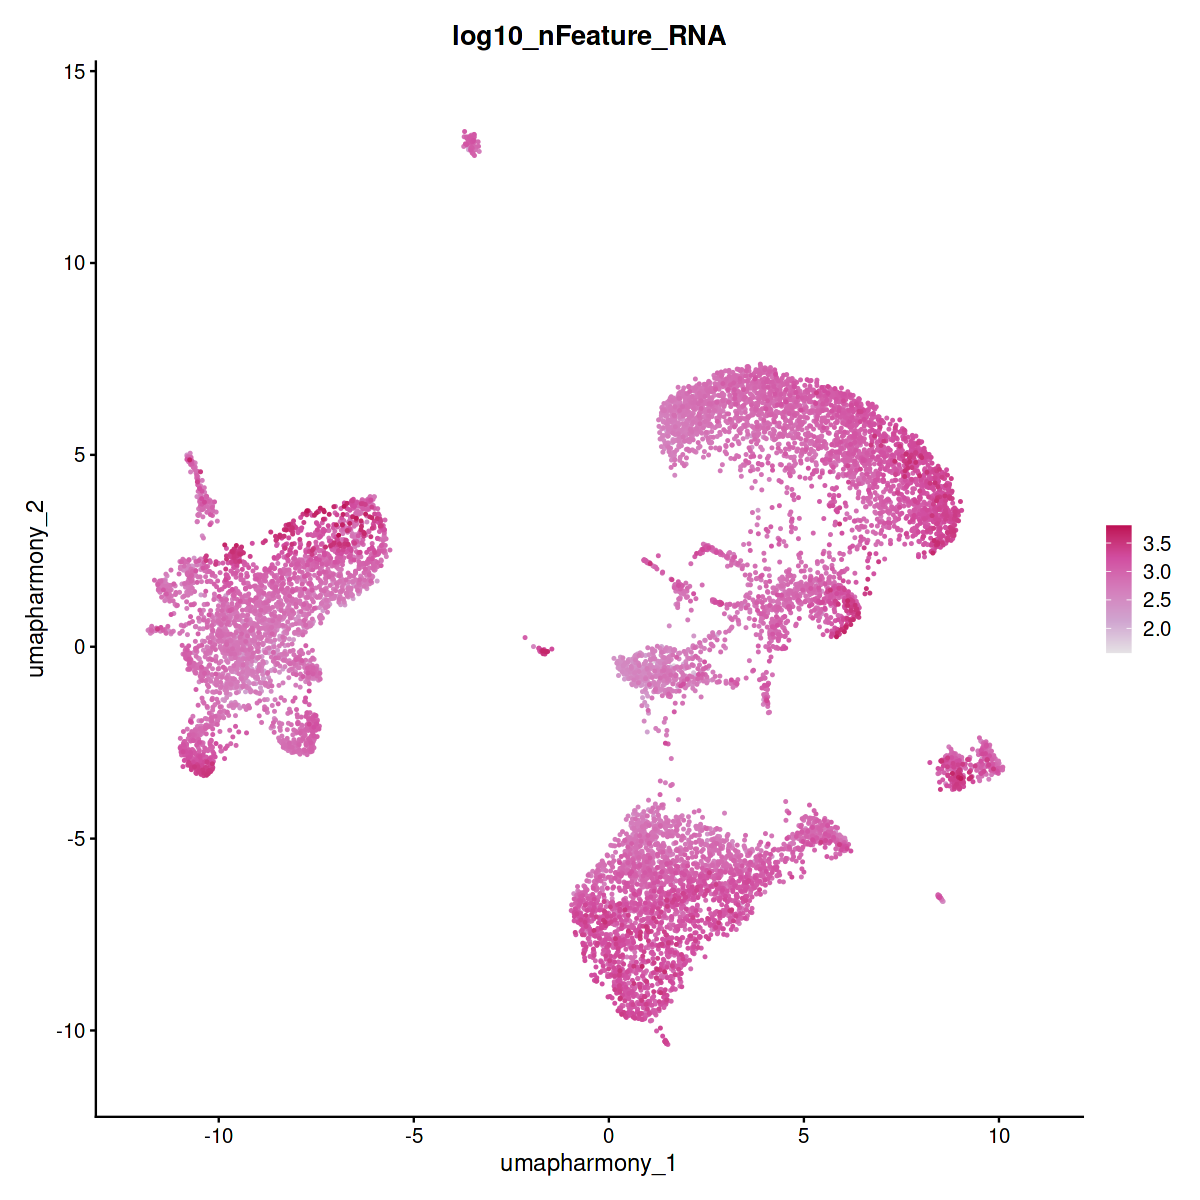

In [44]:
# Hcon harmony-integrated UMAP showing nFeature_RNA
options(repr.plot.width=10, repr.plot.height=10)
FeaturePlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE,
            features = "log10_nFeature_RNA", order = TRUE) +
  scale_colour_gradientn(colours = c("#E5E2E5", "#D0A5D0", "#D47DBB", "#D14DA0","#BD0E54"))
ggsave(file = "05_figures/hcon_UMAP_nFeature_RNA.png", width = 20, height = 20, dpi = 600, units = "cm")

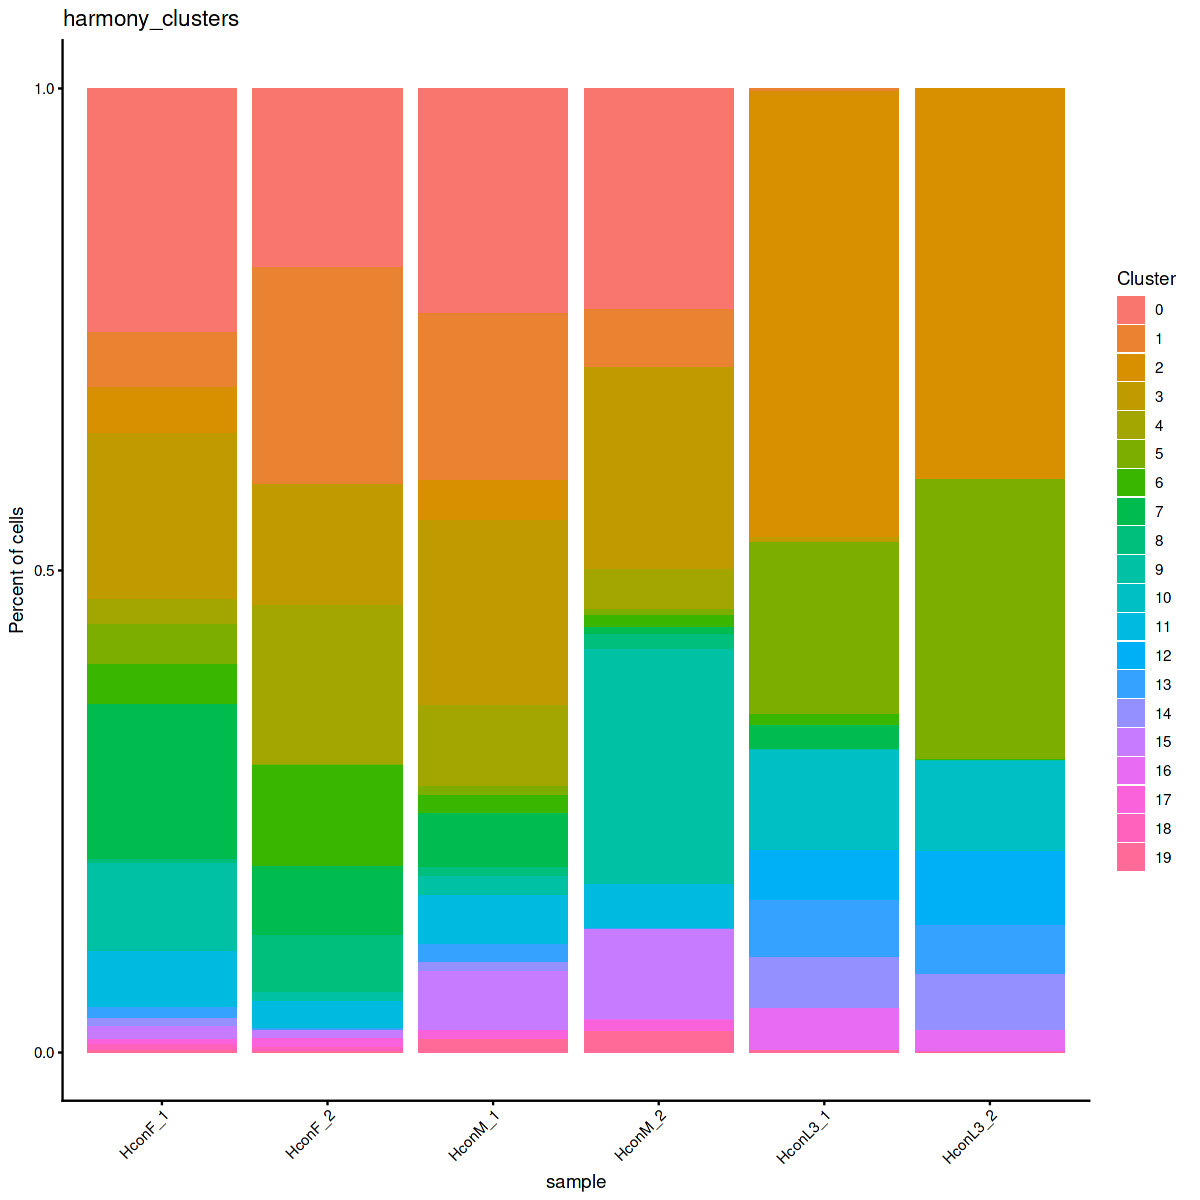

In [95]:
# Hcon frequency plot for nuclei count in each cluster per sample
dittoBarPlot(object = Hcon_obj, var = "harmony_clusters", 
             group.by = "sample", scale = "percent",
             legend.title = "Cluster", color.panel = seurat_20_colors,
             x.reorder = c(1, 2, 5, 6, 3, 4), 
             var.labels.reorder = c(1,2,13,14,15,16,17,18,19,20,3,4,5,6,7,8,9,10,11,12)) 
ggsave(file = "05_figures/hcon_freq.png", width = 20, height = 20, dpi = 600, units = "cm")

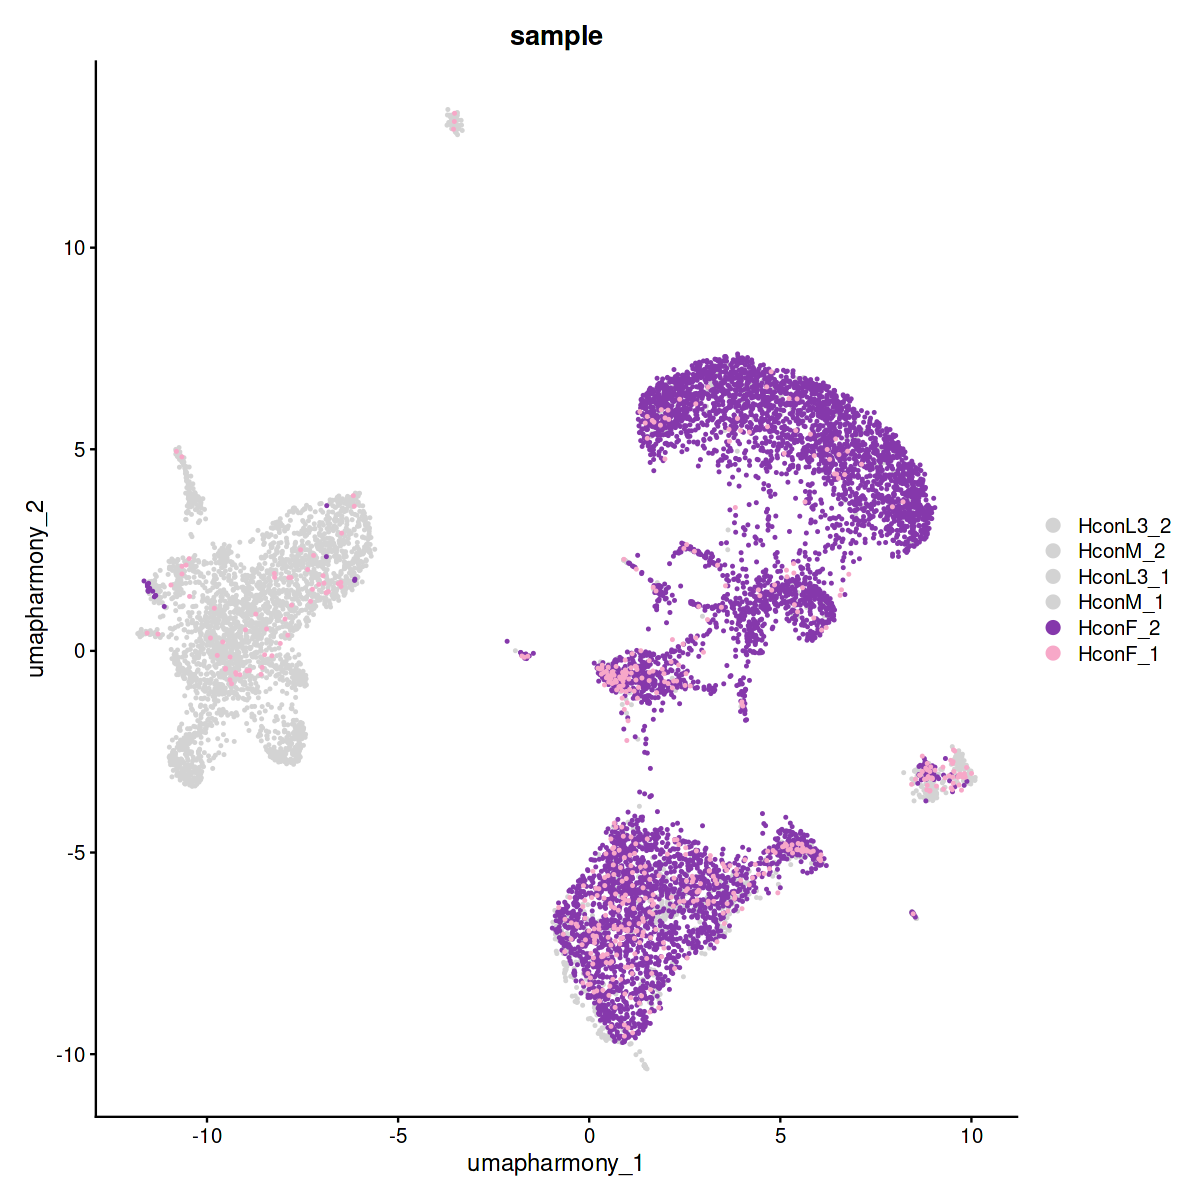

In [105]:
# Hcon female kit 1 vs 2
Fplot_last <- c("HconF_1","HconF_2")

#Sample colors to use
Fstage_cols <- c(
    "HconF_1" = "#F7A8C8",
    "HconF_2" = "#8538AB",
    "HconM_1" = "lightgray",
    "HconM_2" = "lightgray",
    "HconL3_1" = "lightgray",
    "HconL3_2" = "lightgray")

DimPlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE, 
        group.by = "sample",
        order = Fplot_last,
        cols = Fstage_cols)
ggsave(file = "05_figures/hconF_kit.png", width = 20, height = 20, dpi = 600, units = "cm")

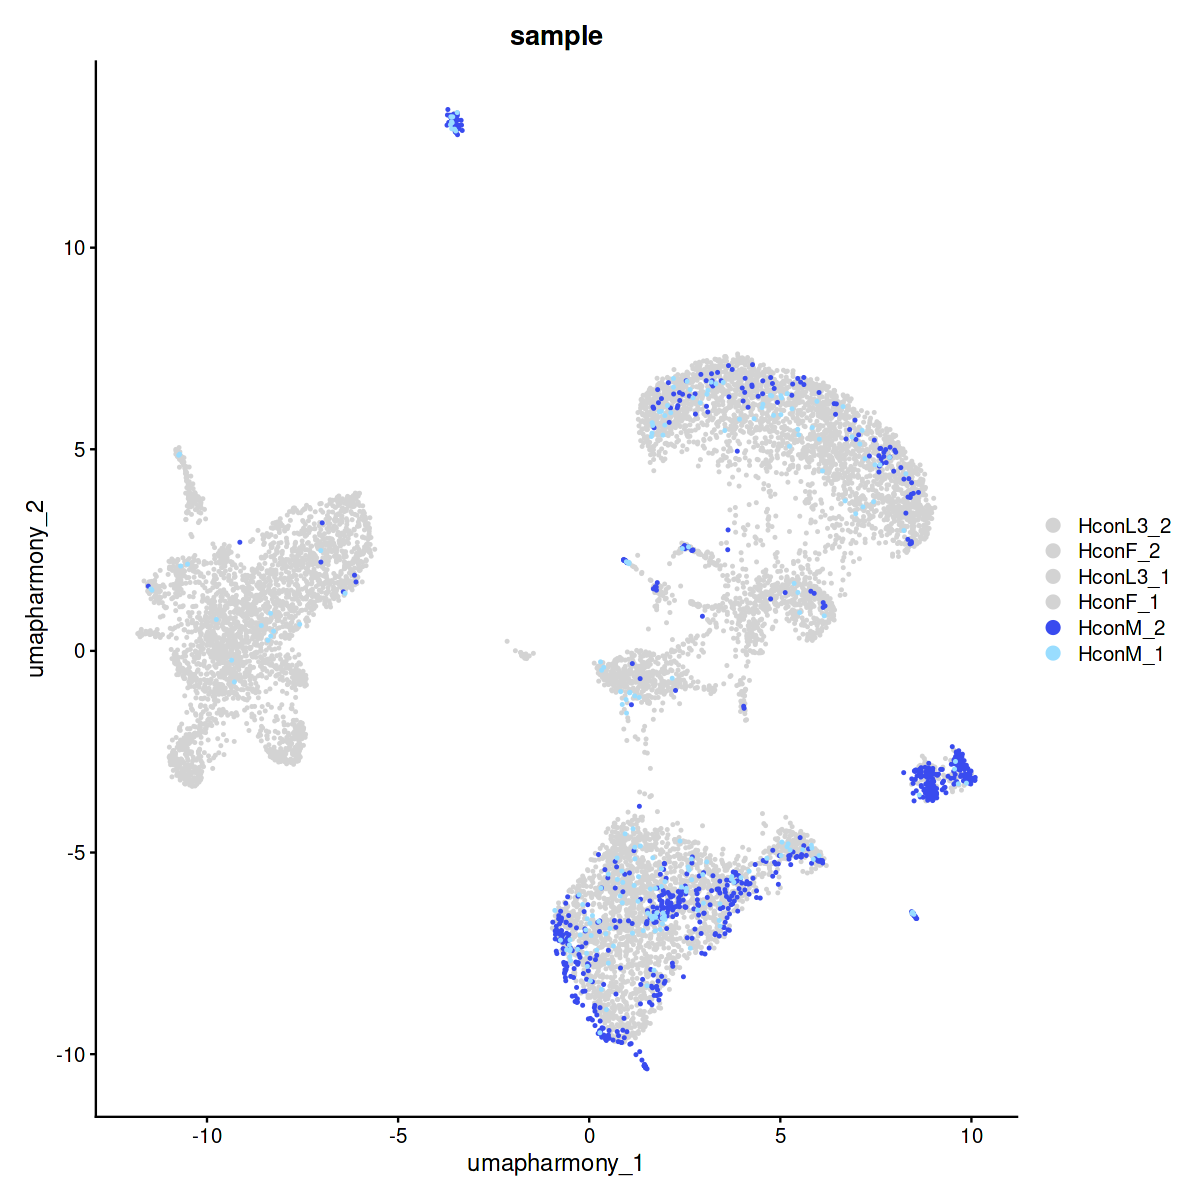

In [103]:
# Hcon male kit 1 vs 2
Mplot_last <- c("HconM_1", "HconM_2")

#Sample colors to use
Mstage_cols <- c(
    "HconF_1" = "lightgray",
    "HconF_2" = "lightgray",
    "HconM_1" = "#99DDFF",
    "HconM_2" = "#394BEF",
    "HconL3_1" = "lightgray",
    "HconL3_2" = "lightgray")

DimPlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE, 
        group.by = "sample",
        order = Mplot_last,
        cols = Mstage_cols)
ggsave(file = "05_figures/hconM_kit.png", width = 20, height = 20, dpi = 600, units = "cm")

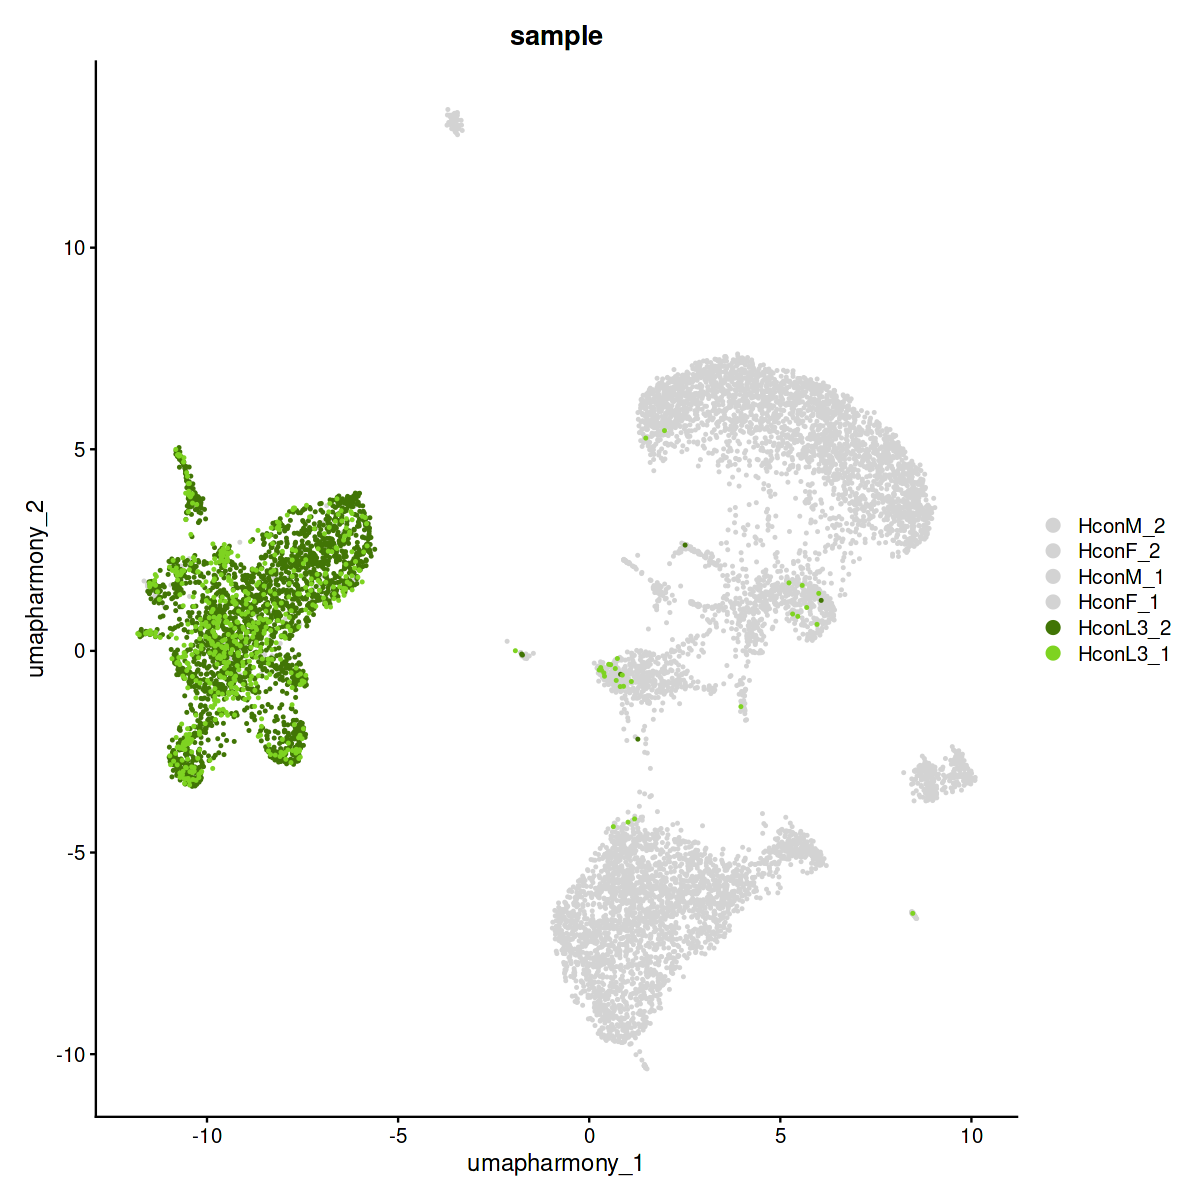

In [106]:
# Hcon L3 kit 1 vs 2
L3plot_last <- c("HconL3_1", "HconL3_2")

#Sample colors to use
L3stage_cols <- c(
    "HconF_1" = "lightgray",
    "HconF_2" = "lightgray",
    "HconM_1" = "lightgray",
    "HconM_2" = "lightgray",
    "HconL3_1" = "#7ED321",
    "HconL3_2" = "#417505")

DimPlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE, 
        group.by = "sample",
        order = L3plot_last,
        cols = L3stage_cols)
ggsave(file = "05_figures/hconL3_kit.png", width = 20, height = 20, dpi = 600, units = "cm")